<a href="https://colab.research.google.com/github/FekadeTafess/Automobile-Price-Fuel-Economy-Analysis/blob/main/Automobile_Data_Project_BTA_522__Fekade_Tafess.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Step 1: Goal and Questions
Goal: the goal for this project is to explore certain makes of cars and how price and fuel economy vary across makes, body styles, and drive types. I believe that a modern audience or people who are car enthusiasts (people interested in classic cars or students of automotive history) get a better grasp of how older vehicles dealt with previous price points. I chose this data set since it gives me a good amount numerous categorical variables and continuous variables

Pre-Analysis Questions:

1. Does an engine with more cylinders or more horsepower tend to cost more? (price, num_of_cylinders, horsepower)

2. Do diesel cars get better mileage than gas cars and do they cost more? (city_mpg, highway_mpg, fuel_type, price)

3. How does price differ by body style and drive wheels? (price, body_style, drive_wheels).

Step 2: Data Description:

Author: Ramakrishnan Srinivasan Auto-Mobile 1985 Data Analysis
October 25th, 2026     
Source:https://www.kaggle.com/datasets/toramky/automobile-dataset

 **Title:** Automobile Data Set (UCI Machine Learning Repository, 1985 imports)

**Date:** October 2026

**Maintainer:** 1985 Ward's Automotive Yearbook

| Variable Name | Variable Label | Variable Type | Storage Type | Response Codes and Value Labels |
|---|---|---|---|---|
| price | Price of the car (USD) | continuous | float64 | |
| horsepower | Engine horsepower (hp) | continuous | float64 | |
| city_mpg | City fuel economy (miles per gallon) | continuous | int64 | |
| highway_mpg | Highway fuel economy (miles per gallon) | continuous | int64 | |
| num_of_cylinders | Number of engine cylinders | categorical, ordinal | str | two=Two cylinders<br>three=Three cylinders<br>four=Four cylinders<br>five=Five cylinders<br>six=Six cylinders<br>eight=Eight cylinders<br>twelve=Twelve cylinders |
| fuel_type | Type of fuel the car uses | categorical | str | gas=Gasoline<br>diesel=Diesel |
| body_style | Body style of the car | categorical | str | convertible=Convertible<br>hardtop=Hardtop<br>hatchback=Hatchback<br>sedan=Sedan<br>wagon=Station wagon |
| drive_wheels | Which wheels the engine drives | categorical | str | fwd=Front-wheel drive<br>rwd=Rear-wheel drive<br>4wd=Four-wheel drive |

auto_project/
├── data/
│   ├── raw/      (original CSV, never edited)
│   └── clean/    (cleaned data saved as feather)
└── figures/      (optional, saved charts)


In [ ]:
import os
#3 making the folders for the project

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)
os.listdir()

['.config', 'figures', 'data', 'sample_data']

In [ ]:
import pandas as pd
import kagglehub

#4 Reading the Data into Python from Kaggle
path = kagglehub.dataset_download("toramky/automobile-dataset")
print(path)

df = pd.read_csv(path + "/Automobile_data.csv", na_values="?")
df.shape

df.columns = df.columns.str.replace("-", "_")
variables_of_interest = ["price", "horsepower", "city_mpg", "highway_mpg", "num_of_cylinders", "fuel_type", "body_style", "drive_wheels"]

df[variables_of_interest].dtypes
df[variables_of_interest].head()



Using Colab cache for faster access to the 'automobile-dataset' dataset.
/kaggle/input/automobile-dataset


,price,horsepower,city_mpg,highway_mpg,num_of_cylinders,fuel_type,body_style,drive_wheels
0,13495.0,111.0,21,27,four,gas,convertible,rwd
1,16500.0,111.0,21,27,four,gas,convertible,rwd
2,16500.0,154.0,19,26,six,gas,hatchback,rwd
3,13950.0,102.0,24,30,four,gas,sedan,fwd
4,17450.0,115.0,18,22,five,gas,sedan,4wd


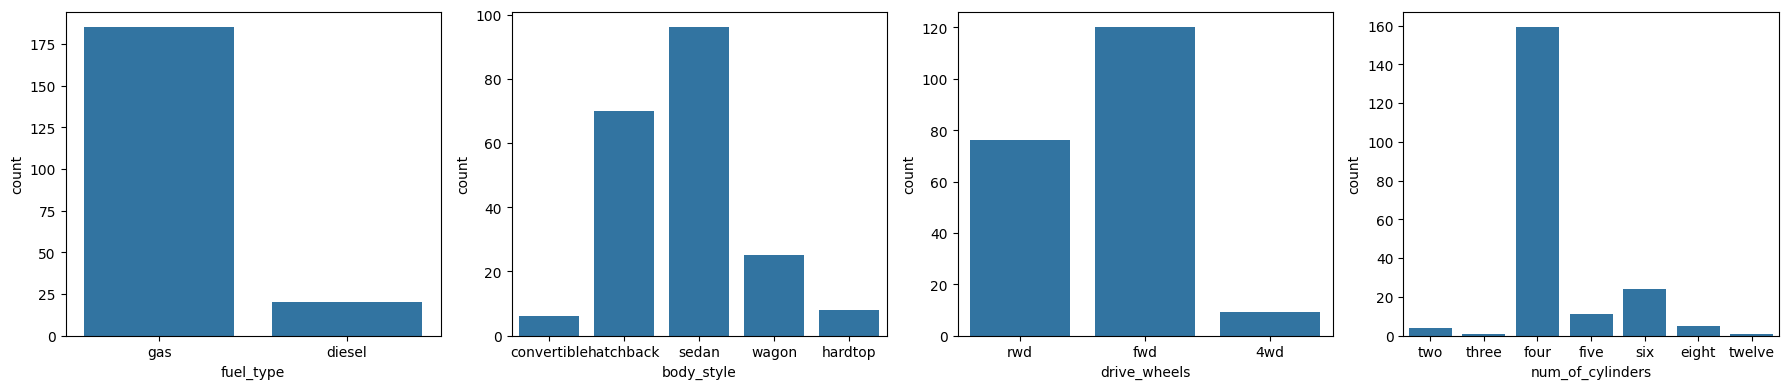

In [ ]:
#5 Cleaning the dataset (Do any needed data cleaning such as making categorical responses consistent for a variable) Verify that each categorical variable in your analysis has "clean" data, such as with a bar chart.
import matplotlib.pyplot as plt
import seaborn as sns

#all data categorical variables are clean from doing my analysis
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

sns.countplot(data=df, x="fuel_type", ax=axes[0])
sns.countplot(data=df, x="body_style", ax=axes[1])
sns.countplot(data=df, x="drive_wheels", ax=axes[2])
sns.countplot(data=df, x="num_of_cylinders", ax=axes[3],
              order=["two", "three", "four", "five", "six", "eight", "twelve"])
plt.tight_layout()
plt.show()


In [ ]:
#6 Convert all categorical variables of interest, integer or character value, type category (Pandas).
#convert the categorical variables to category type

df["fuel_type"] = df["fuel_type"].astype("category")
df["body_style"] = df["body_style"].astype("category")
df["drive_wheels"] = df["drive_wheels"].astype("category")
df["num_of_cylinders"] = df["num_of_cylinders"].astype("category")

df[["fuel_type", "body_style", "drive_wheels", "num_of_cylinders"]].dtypes


,0
fuel_type,category
body_style,category
drive_wheels,category
num_of_cylinders,category


In [ ]:
#7	Do some other variable transformations, even if just changing units for continuous variables or re-coding the levels of categorical variables.
#Transformations of variables
#price in thousands of dollars
df["price_k"] = df["price"] / 1000
df[["price", "price_k"]].head()



,price,price_k
0,13495.0,13.495
1,16500.0,16.500
2,16500.0,16.500
3,13950.0,13.950
4,17450.0,17.450


In [ ]:
#turning a price into section groups (automobile price points)
df["price_group"] = pd.cut(df["price"],
                           bins=[0, 10000, 20000, 30000],
                           labels=["Low", "Medium", "High"])
df[["price", "price_group"]].head()

,price,price_group
0,13495.0,Medium
1,16500.0,Medium
2,16500.0,Medium
3,13950.0,Medium
4,17450.0,Medium


In [ ]:
import numpy as np
#Take the log of price.
df["log_price"] = np.log(df["price"])
df[["price", "log_price"]].head()

,price,log_price
0,13495.0,9.510075
1,16500.0,9.711116
2,16500.0,9.711116
3,13950.0,9.543235
4,17450.0,9.767095


In [ ]:
#8 Subset the full data set to just variables of interest.
my_variables_of_interest = ["price", "horsepower", "city_mpg", "highway_mpg", "num_of_cylinders", "fuel_type",
                            "body_style", "drive_wheels"]
auto = df[my_variables_of_interest].copy()

auto.shape
auto.head()



,price,horsepower,city_mpg,highway_mpg,num_of_cylinders,fuel_type,body_style,drive_wheels
0,13495.0,111.0,21,27,four,gas,convertible,rwd
1,16500.0,111.0,21,27,four,gas,convertible,rwd
2,16500.0,154.0,19,26,six,gas,hatchback,rwd
3,13950.0,102.0,24,30,four,gas,sedan,fwd
4,17450.0,115.0,18,22,five,gas,sedan,4wd


In [ ]:
# target missing values for price and horsepower
auto.isna().sum()

auto[auto["price"].isna() | auto["horsepower"].isna()]


,price,horsepower,city_mpg,highway_mpg,num_of_cylinders,fuel_type,body_style,drive_wheels
9,NaN,160.0,16,22,five,gas,hatchback,4wd
44,NaN,70.0,38,43,four,gas,sedan,fwd
45,NaN,70.0,38,43,four,gas,sedan,fwd
129,NaN,288.0,17,28,eight,gas,hatchback,rwd
130,9295.0,NaN,23,31,four,gas,wagon,fwd
131,9895.0,NaN,23,31,four,gas,hatchback,fwd


In [ ]:
rows_before = len(auto)
auto = auto.dropna(subset=["price", "horsepower"])
auto = auto.reset_index(drop=True)
print(rows_before, "rows before", len(auto), "rows_after")

205 rows before 199 rows_after


In [ ]:
#9 Write the cleaned data to a feather file into the data folder for reading back into Pandas for the actual data analysis.
auto.isna().sum()
auto.dtypes


,0
price,float64
horsepower,float64
city_mpg,int64
highway_mpg,int64
num_of_cylinders,category
fuel_type,category
body_style,category
drive_wheels,category


In [ ]:
import os
import pandas as pd

# Ensure the data directory exists before saving
os.makedirs("data", exist_ok=True)

auto.to_feather("data/auto_clean.feather")
auto_clean = pd.read_feather("data/auto_clean.feather")

print("Dataframe successfully saved and loaded!")
print("Shape:", auto_clean.shape)
display(auto_clean.head())

Dataframe successfully saved and loaded!
Shape: (199, 8)


,price,horsepower,city_mpg,highway_mpg,num_of_cylinders,fuel_type,body_style,drive_wheels
0,13495.0,111.0,21,27,four,gas,convertible,rwd
1,16500.0,111.0,21,27,four,gas,convertible,rwd
2,16500.0,154.0,19,26,six,gas,hatchback,rwd
3,13950.0,102.0,24,30,four,gas,sedan,fwd
4,17450.0,115.0,18,22,five,gas,sedan,4wd


***NOTE***: After step 8, I noticed the categorical variables in my subset were still type object. The conversion in step 6 had been applied to df, but my subset auto was created before that.In the following cells I rebuilt auto from the converted df, dropped the rows with missing values again, and confirmed with auto.dtypes that all four show category before saving to feather.

In [ ]:
auto = df[my_variables_of_interest].copy()

In [ ]:
auto = auto.dropna(subset=["price", "horsepower"])
auto = auto.reset_index(drop=True)
auto.shape

(199, 8)

In [ ]:
#writing my variables of interest as category
auto.dtypes

,0
price,float64
horsepower,float64
city_mpg,int64
highway_mpg,int64
num_of_cylinders,category
fuel_type,category
body_style,category
drive_wheels,category


In [ ]:
#10.	For merging, either read two different data sets into Pandas data frames with a common variable and merge. Or, artificially create two data sets by doing a subsetting by moving some variables into one new data frame and the remaining variables into the other newly created data frame. Then merge back into a single data frame as if the data had arrived in separate files. Following that procedure provides examples of both subsetting and merging data frames.
#engine and fuel economy frame
auto_clean["car_id"] = auto_clean.index
engine_data = auto_clean[["car_id", "horsepower", "num_of_cylinders", "city_mpg", "highway_mpg"]]
engine_data.head()



,car_id,horsepower,num_of_cylinders,city_mpg,highway_mpg
0,0,111.0,four,21,27
1,1,111.0,four,21,27
2,2,154.0,six,19,26
3,3,102.0,four,24,30
4,4,115.0,five,18,22


In [ ]:
#Price and car type frame
car_data = auto_clean[["car_id", "price", "fuel_type", "body_style", "drive_wheels"]]
car_data.head()

,car_id,price,fuel_type,body_style,drive_wheels
0,0,13495.0,gas,convertible,rwd
1,1,16500.0,gas,convertible,rwd
2,2,16500.0,gas,hatchback,rwd
3,3,13950.0,gas,sedan,fwd
4,4,17450.0,gas,sedan,4wd


In [ ]:
#merging both data points into one frame
auto_merged = pd.merge(engine_data, car_data, on="car_id")
auto_merged.head()

,car_id,horsepower,num_of_cylinders,city_mpg,highway_mpg,price,fuel_type,body_style,drive_wheels
0,0,111.0,four,21,27,13495.0,gas,convertible,rwd
1,1,111.0,four,21,27,16500.0,gas,convertible,rwd
2,2,154.0,six,19,26,16500.0,gas,hatchback,rwd
3,3,102.0,four,24,30,13950.0,gas,sedan,fwd
4,4,115.0,five,18,22,17450.0,gas,sedan,4wd


In [ ]:
auto_merged.shape

(199, 9)

In [ ]:
auto_merged.dtypes

,0
car_id,int64
horsepower,float64
num_of_cylinders,category
city_mpg,int64
highway_mpg,int64
price,float64
fuel_type,category
body_style,category
drive_wheels,category


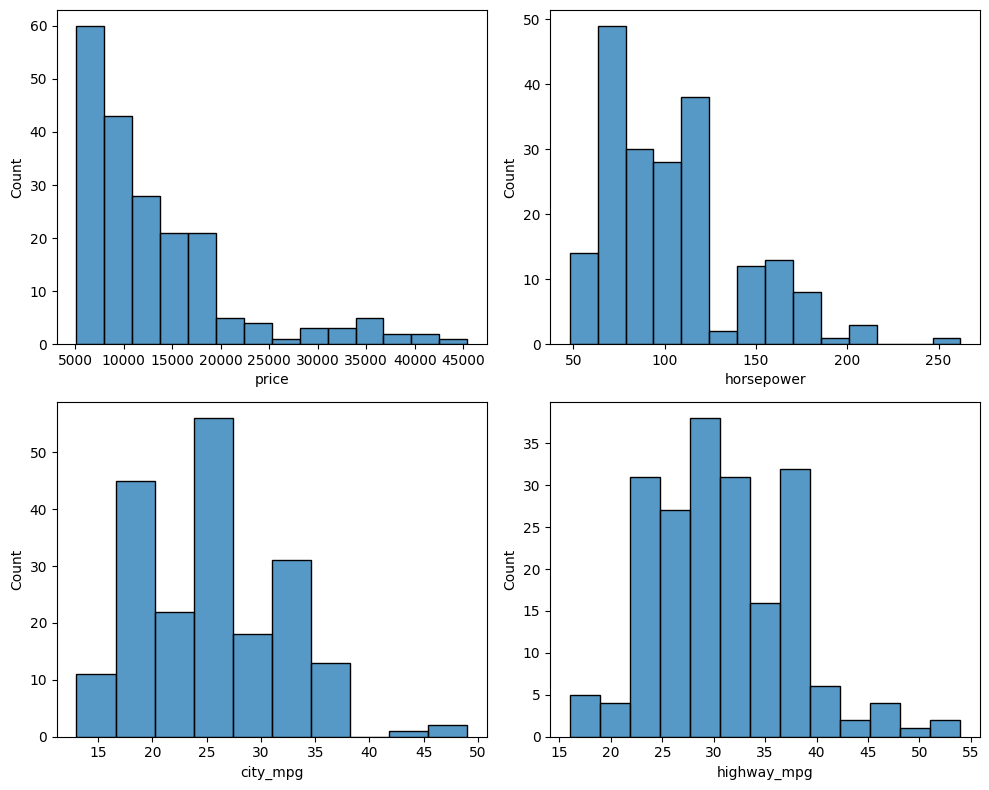

In [ ]:
#11.	Data Analysis I: Display a bar chart or histogram for at least several variables of interest, and comment.
#Histogram for the continuous variables of interest
# price histogram shows a right skew in data trend, showing the bulk of count of cars that are priced at a lower amount, 60 or so cars have a price in the $5,000 region
#Horsepower is also right skewed, with a median of about 95 and a mean near 103.
#City and highway mpg: mildly right-skewed, with most cars in the 20s (city) and 30s (highway).
#Categories: four-cylinder cars, sedans, and gas cars dominate, and the other groups are small.

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

sns.histplot(data=auto_merged, x="price", ax=axes[0, 0])
sns.histplot(data=auto_merged, x="horsepower", ax=axes[0, 1])
sns.histplot(data=auto_merged, x="city_mpg", ax=axes[1, 0])
sns.histplot(data=auto_merged, x="highway_mpg", ax=axes[1, 1])
plt.tight_layout()
plt.show()

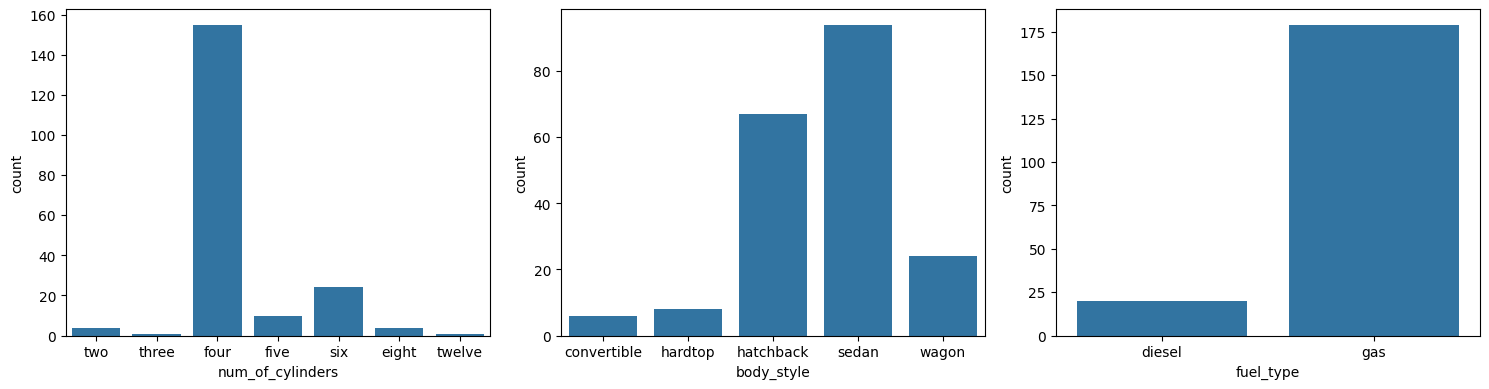

In [ ]:
#bar chart for the categorical variables
#first bar chart on the left shows a count of 140 - 155 cars being 4 cylinder vehicles, that is the most popular car of the 1980s
#the bar graph in the middle shows big amount of hatchback and sedan cars (for bodystyle)
#for fuel type it is evident cars that are gas are the most popular count
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(data=auto_merged, x="num_of_cylinders", ax=axes[0],
              order= ["two", "three", "four", "five", "six", "eight", "twelve"])
sns.countplot(data=auto_merged, x="body_style", ax=axes[1])
sns.countplot(data=auto_merged, x="fuel_type", ax=axes[2])

plt.tight_layout()
plt.show()

In [ ]:
#12.	Data Analysis II: Do a data aggregation and interpret.
#Q1: Does an engine with more cylinders or more horsepower tend to cost more? (price, num_of_cylinders, horsepower)
auto_merged.groupby("num_of_cylinders", observed=True)["price"].agg(["count", "mean", "median"])

#What I see from my analysis is that four cylinder cars are the highest count at 155, and to answer the question,yes the more cylinders a car has the more it does cost.
#the table shows 8 cylinder cars at an average of $38,900 thousand dollars, while the median is listed at $38,008 where 1 cylinder car is listed at $36k


,count,mean,median
num_of_cylinders,,,
eight,4,38900.000000,38008.0
five,10,22007.600000,21397.5
four,155,10312.335484,8948.0
six,24,23671.833333,21037.5
three,1,5151.000000,5151.0
twelve,1,36000.000000,36000.0
two,4,13020.000000,12745.0


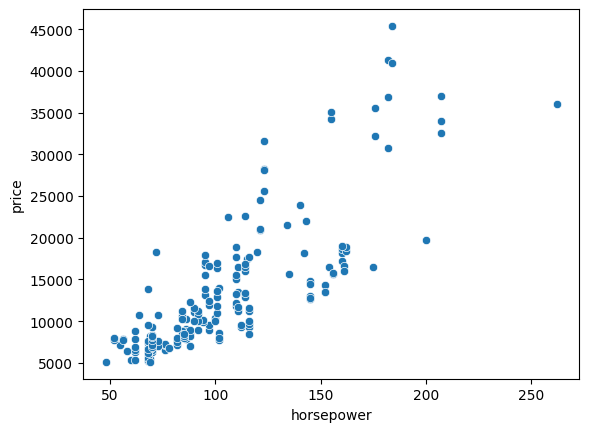

In [ ]:
auto_merged[["price", "horsepower"]].corr()
sns.scatterplot(data=auto_merged, x="horsepower", y="price")
plt.show()
#the correlation between price and horsepower is 0.81 this shows that a close correlation the stronger horsepower is linked with more expenisve engine

In [ ]:
#Q2: Do diesel cars get better mileage than gas cars and do they cost more? (city_mpg, highway_mpg, fuel_type, price)
auto_merged.groupby("fuel_type", observed=True)[["city_mpg", "highway_mpg", "price"]].mean()

,city_mpg,highway_mpg,price
fuel_type,,,
diesel,30.300000,34.75000,15838.150000
gas,24.631285,30.22905,12953.519553


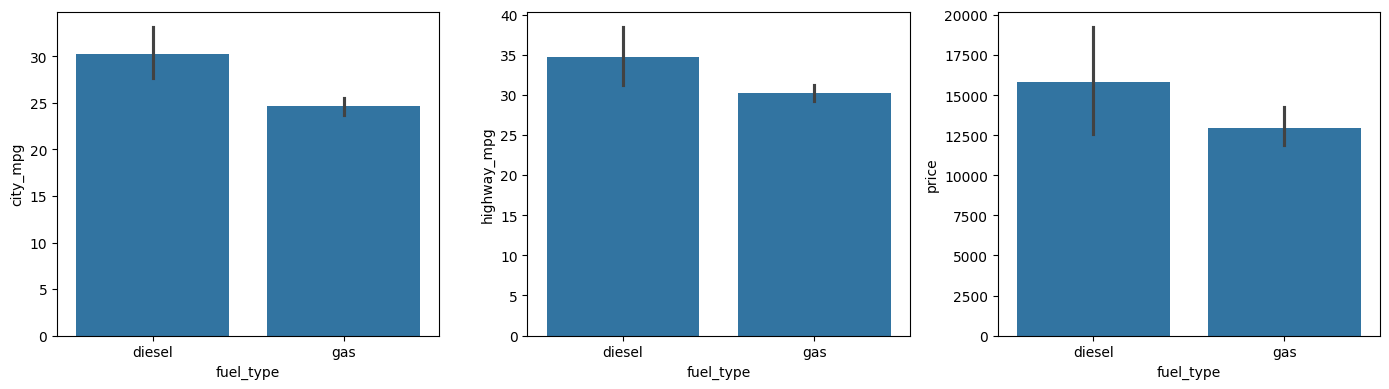

In [ ]:
#bar graph showing the difference in mileage gas vs diesal cars (cost gas vs diesel)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sns.barplot(data=auto_merged, x="fuel_type", y="city_mpg", ax=axes[0])
sns.barplot(data=auto_merged, x="fuel_type", y="highway_mpg", ax=axes[1])
sns.barplot(data=auto_merged, x="fuel_type", y="price", ax=axes[2])

plt.tight_layout()
plt.show()

In [ ]:
#Q3: How does price differ by body style and drive wheels? (price, body_style, drive_wheels).
#Price by Bodystyle
auto_merged.groupby("body_style", observed=True)["price"].agg(["count", "mean", "median"])



,count,mean,median
body_style,,,
convertible,6,21890.500000,17084.5
hardtop,8,22208.500000,19687.5
hatchback,67,9958.373134,8499.0
sedan,94,14459.755319,11078.5
wagon,24,12500.166667,11992.0


In [ ]:
#Price by Wheel Drives of cars. (Rwd, Awd, Fwd)
auto_merged.groupby("drive_wheels", observed=True)["price"].agg(["count", "mean", "median"])


,count,mean,median
drive_wheels,,,
4wd,8,10241.000000,9005.5
fwd,116,9238.741379,8094.0
rwd,75,19757.613333,16900.0


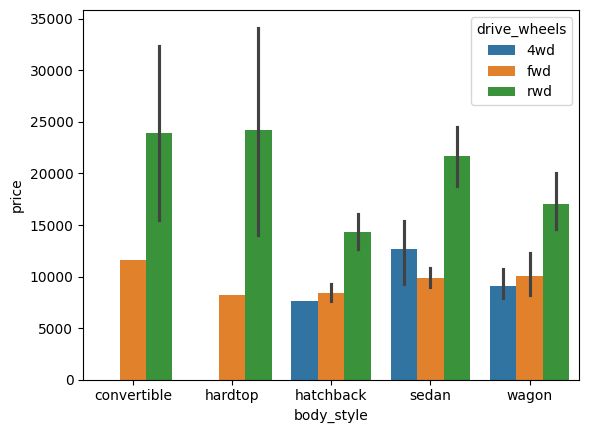

In [ ]:
#Barchart that cover the value of price for both bodystyle and wheele drive for cars
sns.barplot(data=auto_merged, x="body_style", y="price", hue="drive_wheels")
plt.show()

**Step 13:**	As part of iterative EDA, use Data Analysis I & II insights to fine-tune your original 2-3 questions, and frame 2 questions that are the next steps that you would look into and why they matter.   No new coding is expected for these questions.


Part 1: Fine-tuning the original questions. Describe each question as it was, then how it should change.

1. Does an engine with more cylinders or more horsepower tend to cost more? (price, num_of_cylinders, horsepower), (from my analysis It is evident the more cylinders a car has the more cost in price shoots up, so I could focus my question around cylinders and engine type cause price to change?)


2. Do diesel cars get better mileage than gas cars and do they cost more? (city_mpg, highway_mpg, fuel_type, price) (from this analysis I did find that diesel cars have hihgher cost in miles per gallon in the city and the highway, what can be changed is adding horsepower to the question, does the use or wear on the engine cause the certain cars to cost more?

3. How does price differ by body style and drive wheels? (price, body_style, drive_wheels). (Hardtop cars have are the most expensive bodystyle in a car, while rear wheel drive cars are the most the most expensive in (rear wheel drive cars are the most expensive across all body styles.)

Part 2: Two new next-step questions. Each needs the question, why it matters, and who it matters to, tied to the audience you named in step 1.
Q1: Do cars with larger engines get worse mileage, and does that relationship differ between gas and diesel cars? (variables:engine_size, city_mpg, highway_mpg, fuel_type, make)

Q2: Which car make have the most effective engine size, or peak rpm on average city_mpg? (variables: rpm, engine size, city_mpg)

**Step 14:** Generative AI Evaluation:

Your step 1 goal and audience: what the project is for, who you imagine reading the findings, and why.


*   The Goal of this project is analyze an older data set that is the 1985 Automobile data, as a stated before my target audience are people who are car enthusiasts (people interested in classic cars or students of automotive history) or individuals that work in the car automotive industry who wrote research reports different cars from different time periods.I think this analysis project would be important todays findings when comparing price points, or the efficiency of diesel vs gas cars when research previous miles per gallon on the highway vs city. Since we live in a modern era certain historians could take this data and use for live reports on historic trends. Companies that dominate todays market Toyota, Ford, Honda, Alfa Romeo, Porsche, Chevorlet, BMW may wan to use the data for researhc targeting their own present sales and trends, engine types, diesel cars, horsepower, vs the gas cars and make high performance vehicles for the future.

The questions that I targeted were:

1. Does an engine with more cylinders or more horsepower tend to cost more? (price, num_of_cylinders, horsepower)

2. Do diesel cars get better mileage than gas cars and do they cost more? (city_mpg, highway_mpg, fuel_type, price)

3. How does price differ by body style and drive wheels? (price, body_style, drive_wheels).

Evaluation from Claude AI (AI use statement)

my stated goal mentions makes, but your analysis never uses make, so the goal and the analysis don’t match.

ther were some errors that was focused around the cost “$38,900 thousand,” a “1 cylinder” group that doesn’t exist, and a “more cylinders means higher price” claim your own table doesn’t fully support because of the tiny groups.

“Most popular car” overstates what a count in this dataset shows, and “Awd” should be four-wheel drive (4wd).

Some numbers in your comments werent displayed in the correct manner

When I read over some sections in part 13 my goal of the project soundsed like I was giving advice to people wanting to understand my project analysis. I could probably have worked better on the wording when assembling my approach to the explaining the project.

**STEP 15:** Generative AI Follow-Up: Reflect on the feedback from #14. What are your takeaways from the Generative AI feedback? Did you accomplish your goal?

Yes I think I did accomplish my goal as I was looking at my analysis I found that my questions were answered thoroughly, I worked around strengthen my questions of what I could do better. Considering how to tackle my goals for the project the target audience": Ai statement:The goal doesn’t match what you analyzed. It says you’ll explore “certain makes of cars” and how price and fuel economy vary “across makes, body styles, and drive types.” But make isn’t one of your 8 variables, and fuel economy is only compared by fuel type, not by body style or drive type. A reviewer would catch this right away.
“Why they care” is vague. “A better grasp of how older vehicles dealt with previous price points” doesn’t say what this audience would learn from your results. For example, what would an enthusiast or historian want to know about 1985 imports’ prices, or about efficiency versus power?

 Did the feedback bring up anything relevant that you missed? What revisions would you make based on the feedback?

 I think overall it covered evrything that I did an analysis for, the things i missed were probably considering the bar charts or histograms that may needed some tweaking but overall I think it got most parts correct. There are diffetent charty types scatterplots show inconsistency, In  my goal I stated make was a variable that I could have used in my analysis (I missed out on) I should have explored,